# 13 · A human approval gate with interrupt and resume, as a LangGraph graph
Level L3 · Part 3 · core · ~25 min · builds on 06, 09

## Goal
Pause a refund before it is paid, wait for a person, and resume the same run safely, as a LangGraph graph. The refund is
paid once, even when the process restarts or a resume is sent twice. The graph is drawn from its code, and each step of
the run is saved.

## Why it matters
Lesson 09 held the refund in a Python list, `PENDING`. That list lives inside one process. Run the block below: the
refund goes out as soon as it is asked for, with no pause and no person. A retry after a timeout pays it again.
**Nothing in this block waits for anyone.**

In [1]:
REFUNDS = []  # what the money has really done


def naive_refund(order_id: str, amount_usd: float) -> str:
    REFUNDS.append((order_id, amount_usd))  # the money moves here, with no pause
    return "refunded"


# The first reply times out after the money has moved. The agent cannot tell, so it asks again.
naive_refund("2207", 84.00)
naive_refund("2207", 84.00)  # the retry: nothing remembers the first call
print("refunds made:", len(REFUNDS), "· paid out:", sum(a for _, a in REFUNDS), "USD for an 84.00 USD order")

refunds made: 2 · paid out: 168.0 USD for an 84.00 USD order


**What it makes easy:** a refund waits as saved state, not as a running program. The reviewer can come back an hour
later, a restart loses nothing, and a repeated resume cannot pay twice. **When you don't need it:** a read-only tool
changes nothing, so it needs no gate. A write under a small limit may be allowed without a person; the rule is yours.

## The idea
In LangGraph the gate is an **`interrupt()`** in the approval node. The run stops there, and the **checkpointer** saves its
state in a SQLite file under a **thread id**. A reviewer resumes the thread later with `Command(resume=...)`, from any
process. Three rules keep it safe:

- **Escalation** is an edge: a refund above the limit goes back to the approval node until a senior lead decides.
- The **payment** is recorded under the thread id as its **idempotency key**, so a second payment with the same key does
  nothing.
- A **finished** run has nothing left to run, so a repeated resume pays nothing.

Analogy: a cheque with a second signature. The clerk puts it in a tray, not in the till. The manager signs it later. The
clerk checks the tray before paying, and a cheque stamped "paid" is never paid again.

## Picture
The graph below is drawn in Step 3 from the code. The pause is the `approval` node, and the escalation is the loop from
`refuse` back to `approval`. In the picture, blue nodes run code and the amber node calls the model. The picture needs
internet access; without it, the cell prints the same graph as text.

## Step by step
Six steps. Steps 1 to 3 build the store, the graph and its picture. Steps 4 to 6 run the refunds. Only Step 4 calls the
model, and only once.

**Step 1 · the store and the rules (setup, no call).** The graph saves its state in a SQLite file from the standard library,
and the ledger of payments lives in the same file. Orders are fictional, as in lessons 06 to 09. A refund above $50 needs a
senior lead: that is the escalation rule. The cell deletes the file first, so every run starts clean.

In [2]:
import sqlite3
from pathlib import Path

DB = Path("../../../data/13_approval/approvals.db")
DB.parent.mkdir(parents=True, exist_ok=True)  # run-time files for this lesson
DB.unlink(missing_ok=True)                    # start with no saved runs
ORDERS = {"1093": 45.00, "2207": 84.00}       # fictional order totals, as in lessons 06 to 09
SENIOR_LIMIT_USD = 50.00                      # above this amount, only senior-lead may decide
with sqlite3.connect(DB) as db:
    db.execute("CREATE TABLE IF NOT EXISTS ledger (idem_key TEXT PRIMARY KEY, order_id TEXT, amount_usd REAL)")
print("store ready:", DB.name)

store ready: approvals.db


**Step 2 · the state and the nodes.** The state is the record of one refund: the proposal, the reviewer's decision, the
note from an escalation refusal, and the status. The `propose` node is the only place the model is called. `approval`
is the pause. `pay` writes the ledger row keyed on the thread id and returns the status. Each node returns only what it
changes.

Two course helpers appear first in the model cell below, and both are explained here once. `llm_replay` records the
model's answers on the first run and replays them later, so the lesson runs offline with no key. `get_llm()` is the
course's shared model setup, which returns the chat model at temperature 0.

In [3]:
import sys; sys.path.insert(0, "../../..")
import llm_replay  # course helper: records and replays model calls (not part of LangGraph)
from llm_setup import get_llm  # course helper: the course's shared model setup
from pydantic import BaseModel, Field

llm_replay.start("13_human-approval-gate")
llm = get_llm()


class ProposeRefund(BaseModel):
    """Propose a refund. A person must approve it before any money moves."""
    order_id: str = Field(description="The order number, digits only.")
    amount_usd: float = Field(description="The amount to refund, in USD.")


llm_tools = llm.bind_tools([ProposeRefund])  # the one tool the model sees: it proposes, it cannot pay

LLM mode: replay (13_human-approval-gate.yaml)


Gemini on Vertex AI · API key loaded: True


*The imports, the state and the prompt. No model call here.*

In [4]:
from typing import Literal, TypedDict

from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.runnables import RunnableConfig
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt
from langgraph.checkpoint.sqlite import SqliteSaver

SYSTEM = ("You are the support assistant for Brightside Outfitters. You cannot pay refunds: "
          "call propose_refund, and a person approves it.")
FLAKY = {}  # "crash_after_record": True makes the next payment fail after it is recorded (Step 6)


class RefundState(TypedDict):
    message: str  # the customer's message, for the model
    proposal: dict  # {"order_id", "amount_usd"}: from the model's tool call, or typed in for a demo
    reviewer: str  # who decided the last time
    decision: str  # "approve" or "reject", from the reviewer
    note: str  # why the last decision was refused, shown to the next reviewer
    status: str  # "waiting_approval", "rejected" or "paid"
    result: str  # what the payment recorded

*The routing and the model node. `route_start` sends a typed-in proposal straight to approval, and `propose` is the only
function that calls the model.*

In [5]:
def route_start(state: RefundState) -> Literal["propose", "approval"]:
    return "approval" if state.get("proposal") else "propose"  # a typed-in proposal skips the model


def propose(state: RefundState) -> dict:
    reply = llm_tools.invoke([SystemMessage(content=SYSTEM), HumanMessage(content=state["message"])])  # the one call
    if not reply.tool_calls:
        return {"status": "no refund requested"}
    args = reply.tool_calls[0]["args"]
    return {"proposal": {"order_id": args["order_id"], "amount_usd": float(args["amount_usd"])},
            "status": "waiting_approval"}


def route_after_propose(state: RefundState) -> Literal["approval", "__end__"]:
    return "approval" if state.get("proposal") else END

*The pause and the escalation. `approval` stops the run, and `route_after_approval` sends a large amount back to `refuse`.*

In [6]:
def approval(state: RefundState) -> dict:
    """The pause. The run stops here, saved, until a reviewer resumes it with a decision."""
    decision = interrupt({"question": "Approve this refund?", "proposal": state["proposal"], "note": state.get("note", "")})
    return {"reviewer": decision["reviewer"], "decision": decision["decision"]}


def route_after_approval(state: RefundState) -> Literal["pay", "reject", "refuse"]:
    if state["decision"] == "reject":
        return "reject"
    if state["proposal"]["amount_usd"] > SENIOR_LIMIT_USD and state["reviewer"] != "senior-lead":
        return "refuse"  # escalation: only a senior lead may approve this amount
    return "pay"


def refuse(state: RefundState) -> dict:
    return {"note": f"refused: {state['proposal']['amount_usd']:.2f} USD needs senior-lead"}

*The payment and the reject. `pay` is the only node that moves money, and it keys the ledger row on the run id.*

In [7]:
def pay(state: RefundState, config: RunnableConfig) -> dict:
    run_id = config["configurable"]["thread_id"]  # the run id is the idempotency key
    amount, order = state["proposal"]["amount_usd"], state["proposal"]["order_id"]
    with sqlite3.connect(DB) as db, db:  # the key is the primary key: a repeat insert is ignored
        db.execute("INSERT OR IGNORE INTO ledger VALUES (?, ?, ?)", (run_id, order, amount))
    if FLAKY.pop("crash_after_record", False):
        raise RuntimeError("the process died after the payment was recorded, before the status was saved")
    return {"status": "paid", "result": f"paid {amount:.2f} USD for order {order}"}


def reject(state: RefundState) -> dict:
    return {"status": "rejected", "result": f"rejected by {state['reviewer']}; nothing paid"}

*The graph itself. `build_graph` adds the nodes and edges, then attaches the saver it is given.*

In [8]:
def build_graph(saver):
    g = StateGraph(RefundState)
    for name, fn in [("propose", propose), ("approval", approval), ("refuse", refuse), ("pay", pay),
                     ("reject", reject)]:
        g.add_node(name, fn)
    g.add_conditional_edges(START, route_start, {"propose": "propose", "approval": "approval"})
    g.add_conditional_edges("propose", route_after_propose, {"approval": "approval", END: END})
    g.add_conditional_edges("approval", route_after_approval,
                            {"pay": "pay", "reject": "reject", "refuse": "refuse"})
    g.add_edge("refuse", "approval")  # the escalation loop: the next reviewer decides again
    g.add_edge("pay", END).add_edge("reject", END)
    return g.compile(checkpointer=saver)

**Step 3 · compile the graph and draw it (no model call).** `open_app` opens the SQLite file and builds the graph on it. Each
call is a new app object on the same file, which is what a restart looks like: the graph forgets nothing it saved.
First, the drawing helper: `show_graph` is defined in the cell below and draws a compiled graph as a picture.

In [9]:
from IPython.display import Image, display
from langchain_core.runnables.graph import NodeStyles
from langchain_core.runnables.graph_mermaid import draw_mermaid_png

MODEL_STYLE = "classDef model fill:#fde68a,stroke:#b45309"  # amber: a node that calls the model


def show_graph(app, model_nodes=()):
    """Draw the compiled graph as a picture: blue nodes run code, amber nodes call the model.
    The picture comes from the public Mermaid service (mermaid.ink), so it needs internet access."""
    text = app.get_graph().draw_mermaid(node_colors=NodeStyles(
        default="fill:#e0f2fe,stroke:#0369a1", first="fill:#f1f5f9", last="fill:#dcfce7"))
    text += f"\n{MODEL_STYLE}\n" + (f"class {','.join(model_nodes)} model\n" if model_nodes else "")
    try:
        display(Image(draw_mermaid_png(text)))
    except Exception as e:  # offline, or the service is down: the same diagram as text
        print(f"No picture ({type(e).__name__}). The same graph as Mermaid text:\n{text}")

*Now the app itself: `open_app` builds it on the SQLite file, and the last line draws it.*

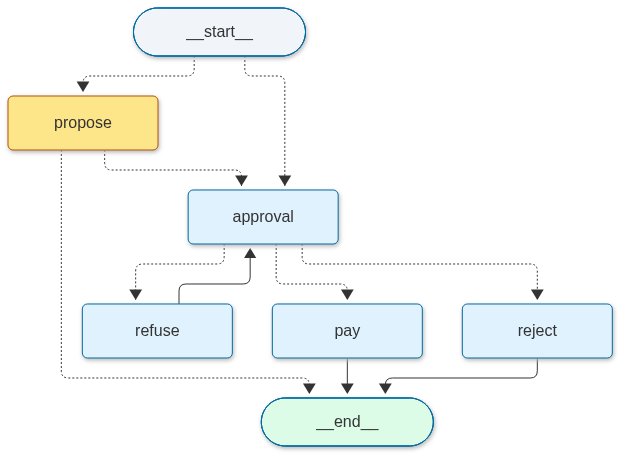

In [10]:
def open_app():
    return build_graph(SqliteSaver(sqlite3.connect(DB, check_same_thread=False)))


app = open_app()
show_graph(app, model_nodes=("propose",))

**Step 4 · process 1: the model proposes, the graph pauses.** A customer asks for a refund. The `propose` node makes one
model call and reads the tool call as the proposal. The graph then reaches `approval` and pauses. Nothing is paid, and
nothing waits in memory: the pause is saved under the thread id.

In [11]:
CUSTOMER = "My parcel for order 2207 arrived with a torn box. Please refund the 84.00 USD I paid."
CFG = {"configurable": {"thread_id": "r-1001"}}
app.invoke({"message": CUSTOMER, "proposal": {}, "reviewer": "", "decision": "", "note": "", "status": "", "result": ""}, CFG)
llm_replay.stop()  # the only model call of this notebook

*The printing for Step 4. If the model cell was skipped, this cell types the same refund in with no model call, so Step 5
still has a paused run to resume.*

In [12]:
if not app.get_state(CFG).next:  # the model cell did not run
    app.invoke({"message": "", "proposal": {"order_id": "2207", "amount_usd": 84.00}, "reviewer": "", "decision": "",
                "note": "", "status": "", "result": ""}, CFG)
print("paused at:", app.get_state(CFG).next, "· proposal:", app.get_state(CFG).values["proposal"])
print("ledger (payments made):", sqlite3.connect(DB).execute("SELECT * FROM ledger").fetchall())

paused at: ('approval',) · proposal: {'order_id': '2207', 'amount_usd': 84.0}
ledger (payments made): []


**Step 5 · process 2: a restart, an escalation, then the payment.** A fresh app object reads the saved pause, as a worker
would after a restart. The support desk's own reviewer tries first: the amount is above $50, so the graph refuses and
pauses again. A senior lead then approves, and the payment runs once. Both resumes are sent to the same thread id.

In [13]:
app = open_app()  # a new process would start here: the saved pause is read from the file
print("after the restart, paused at:", app.get_state(CFG).next)
app.invoke(Command(resume={"reviewer": "agent-desk-1", "decision": "approve"}), CFG)
print("junior reviewer: paused again at", app.get_state(CFG).next, "· note:", app.get_state(CFG).values["note"])
app.invoke(Command(resume={"reviewer": "senior-lead", "decision": "approve"}), CFG)
print("senior lead:", app.get_state(CFG).values["result"])
print("ledger:", sqlite3.connect(DB).execute("SELECT * FROM ledger").fetchall())

after the restart, paused at: ('approval',)
junior reviewer: paused again at ('approval',) · note: refused: 84.00 USD needs senior-lead
senior lead: paid 84.00 USD for order 2207
ledger: [('r-1001', '2207', 84.0)]


**Step 6 · a repeat, a reject, and a crash in the middle of the payment (no model call).** A resume of the paid run returns
the saved result and writes nothing: a finished run has nothing left to run. A second refund is typed in as a proposal
(no model call) and a reviewer rejects it. A third is approved, but the process dies after the payment is recorded and
before the status is saved. The resume runs the node again: the ledger already has that key, so the money moves once.

In [14]:
print("repeat resume (returns the saved result):", app.invoke(None, CFG)["result"])
print("ledger after the repeat:", sqlite3.connect(DB).execute("SELECT * FROM ledger").fetchall())

CFG_REJECT = {"configurable": {"thread_id": "r-1003"}}  # a typed-in proposal: no model call
app.invoke({"proposal": {"order_id": "1093", "amount_usd": 45.00}, "message": "", "reviewer": "", "decision": "",
            "note": "", "status": "", "result": ""}, CFG_REJECT)
app.invoke(Command(resume={"reviewer": "agent-desk-1", "decision": "reject"}), CFG_REJECT)
print("r-1003:", app.get_state(CFG_REJECT).values["result"])

CFG_CRASH = {"configurable": {"thread_id": "r-1002"}}  # a typed-in proposal: no model call
app.invoke({"proposal": {"order_id": "1093", "amount_usd": 45.00}, "message": "", "reviewer": "", "decision": "",
            "note": "", "status": "", "result": ""}, CFG_CRASH)
FLAKY["crash_after_record"] = True
try:
    app.invoke(Command(resume={"reviewer": "agent-desk-1", "decision": "approve"}), CFG_CRASH)
except RuntimeError as e:
    print("crashed:", e)
print("saved status after the crash:", app.get_state(CFG_CRASH).next, "· ledger rows:",
      sqlite3.connect(DB).execute("SELECT COUNT(*) FROM ledger WHERE idem_key = 'r-1002'").fetchone()[0])
app.invoke(None, CFG_CRASH)  # resume: the pay node runs again, and the ledger ignores the repeat
print("r-1002:", app.get_state(CFG_CRASH).values["result"])
print("ledger (one row per paid run):", sqlite3.connect(DB).execute("SELECT * FROM ledger").fetchall())

repeat resume (returns the saved result): paid 84.00 USD for order 2207
ledger after the repeat: [('r-1001', '2207', 84.0)]
r-1003: rejected by agent-desk-1; nothing paid
crashed: the process died after the payment was recorded, before the status was saved
saved status after the crash: ('pay',) · ledger rows: 1
r-1002: paid 45.00 USD for order 1093
ledger (one row per paid run): [('r-1001', '2207', 84.0), ('r-1002', '1093', 45.0)]


## At work
- Production refunds wait in an approval queue, and the reviewer sees the exact arguments that will run. The approver's
  identity is logged with the decision → lesson 31 (agent identity and the audit log).
- A restart must neither lose a pending approval nor pay twice. Teams keep the run state outside the worker and give
  each payment an idempotency key → lesson 32 (idempotency and retries) and lesson 35 (durable runs).
- LangGraph's `interrupt()` saves the run with a checkpointer and resumes it later. Lesson 19 builds the support desk on
  the same pause. Go deeper: Temporal, in lesson 35.

## What just happened
- After the first call the run waits at `approval` for 84.00 USD, and the ledger is empty (`[]`).
- After a restart, the junior reviewer's approval is refused and the run pauses again. The senior lead's approval pays
  84.00 USD once: the ledger has one row.
- The repeat resume returns the saved result, and the ledger still has one row.
- The crash left r-1002 at `pay` with one row. The resume paid 45.00 USD once, so the ledger has two rows, one per paid run.

## Under the hood
The gate needs three things. The **saved state** is the checkpoint, so a new process can read it. The **conditional
update** is what makes one decision win: `WHERE status = 'waiting_approval'` changes the row only if it is still waiting,
and the database does the check and the change in one step. The **idempotency key** is the primary key of the ledger, so a
second insert with the same key is ignored. The demo below uses a scratch database, so the gate's rows stay as they are.

In [15]:
db = sqlite3.connect(":memory:")  # a scratch database for this demo only
db.execute("CREATE TABLE runs (run_id TEXT PRIMARY KEY, status TEXT)")
db.execute("CREATE TABLE ledger (idem_key TEXT PRIMARY KEY, amount_usd REAL)")
db.execute("INSERT INTO runs VALUES ('demo', 'waiting_approval')")
for reviewer in ("agent-desk-1", "second-reviewer"):  # only the first decision matches the WHERE clause
    cur = db.execute("UPDATE runs SET status = 'approved' WHERE run_id = 'demo' AND status = 'waiting_approval'")
    print(reviewer, "decides -> rows changed:", cur.rowcount)  # 1, then 0
for _ in range(2):  # the same key twice: the primary key makes the second insert a no-op
    cur = db.execute("INSERT OR IGNORE INTO ledger VALUES ('demo', 84.0)")
    print("ledger insert -> rows changed:", cur.rowcount)  # 1, then 0
db.close()

agent-desk-1 decides -> rows changed: 1
second-reviewer decides -> rows changed: 0
ledger insert -> rows changed: 1
ledger insert -> rows changed: 0


## Common mistakes
1. **Paying with no key.** Without the run id as the key, a retry inserts a second payment row. The cell below uses a
   plain `INSERT` for a run that is already paid, and the error it raises is printed (name and first line only).

In [16]:
try:
    with sqlite3.connect(DB) as db:
        db.execute("INSERT INTO ledger VALUES ('r-1002', '1093', 45.0)")  # r-1002 is already in the ledger
except Exception as error:  # print the message only: a traceback shows file paths on this machine
    print(type(error).__name__, "-", str(error).splitlines()[0])

IntegrityError - UNIQUE constraint failed: ledger.idem_key


The error names the key, so the duplicate is easy to trace in a log. The fix is the one `pay` uses: the run id is the
primary key, and the insert is `INSERT OR IGNORE`.

2. **The agent approving its own write.** Keep the reviewer's decision out of the agent's tools. The `approval` node
   takes its decision from the reviewer, never from the model.
3. **Keeping the pause in memory.** A Python list is lost when the process ends (lesson 09's `PENDING`). A checkpointer that
   lives in memory (`InMemorySaver`) is lost the same way. The cell below shows it, with no model call.

In [17]:
from langgraph.checkpoint.memory import InMemorySaver

CFG_RAM = {"configurable": {"thread_id": "r-ram"}}
ram_app = build_graph(InMemorySaver())  # the pause is kept in this process's memory only
ram_app.invoke({"proposal": {"order_id": "1093", "amount_usd": 45.00}, "message": "", "reviewer": "", "decision": "",
                "note": "", "status": "", "result": ""}, CFG_RAM)
print("same process, paused at:", ram_app.get_state(CFG_RAM).next)
print("new process, paused at:", build_graph(InMemorySaver()).get_state(CFG_RAM).next)

same process, paused at: ('approval',)
new process, paused at: ()


The new process finds no pause. Use the SQLite saver, as this lesson does, so a restart reads the saved state.

## Try it
Write `needs_senior(amount_usd)` that returns `True` when the amount is above `SENIOR_LIMIT_USD`, and `False` otherwise.
Check it on 45.00, 50.00 and 84.00. Exactly 50.00 does not need a senior, because the rule is "above $50". No model call is
needed.

In [18]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [19]:
def needs_senior(amount_usd: float) -> bool:
    return amount_usd > SENIOR_LIMIT_USD


for amount in (45.00, 50.00, 84.00):
    print(f"{amount:6.2f} USD -> senior needed: {needs_senior(amount)}")

 45.00 USD -> senior needed: False
 50.00 USD -> senior needed: False
 84.00 USD -> senior needed: True


## Key terms
- **Checkpointer** — the LangGraph part that saves a run's state after each step; here, a SQLite file.
- **Thread id** — the id that ties together every saved step of one run.
- **`interrupt()`** — a call inside a node that pauses the run and saves it until someone resumes it.
- **`Command(resume=...)`** — the call that resumes a paused thread and passes in the reviewer's decision.
- **Escalation** — a rule that sends a decision to a higher approver when the amount is above the limit.
- **Idempotency key** — an id that makes a repeated action do nothing the second time; here, the run id.

## Recap
- A refund request is a graph run that pauses at `interrupt()`. The pause is saved, so a restart loses nothing.
- A reviewer resumes the thread with a decision. An amount above the limit loops back until a senior lead decides.
- The payment is recorded under the run id, so a crash and a resume pay once.
- The model proposes, and a person decides. Keep the decision out of the agent's tools.

**Interview:** "A refund needs a manager's approval, and the server can restart at any time. How do you build it?"
Strong answer: "The request is a graph run that pauses for approval, and its state is saved. The manager's decision resumes
the same thread, and an amount over the limit loops back for a senior. The thread id is the payment's idempotency key, so a
restart or a second resume cannot pay twice."